# MODULE 2 — Logique de programmation, NumPy et simulation
**Semaines 3–4 • 6 heures en classe**

## Question directrice
**Pouvez-vous traduire une décision en logique claire, puis appliquer le calcul à grande échelle avec des tableaux NumPy ?**

*Cours conçu par le Professeur BOISGUENE RUBBENS*

### Explication du module
Passer de valeurs isolées à des règles, boucles, fonctions et tableaux numériques pour automatiser des calculs contrôlables, puis utiliser la simulation pour voir la variabilité due au hasard.

### Contenu du module
- *Semaine 3* — Conditions if / elif / else
- *Semaine 3* — Boucles for / while, enumerate et zip
- *Semaine 3* — Fonctions, paramètres et valeurs de retour
- *Semaine 3* — Fichiers, textes bruts et exceptions (try / except)
- *Semaine 4* — NumPy : arrays, formes, types et indexation
- *Semaine 4* — Masques booléens, vectorisation et broadcasting
- *Semaine 4* — Statistiques descriptives avec NumPy
- *Semaine 4* — Générateur aléatoire et simulation : la variabilité d’échantillonnage

### Outils
Python 3, datetime, NumPy (dont le générateur aléatoire), pandas

### Routine de classe
1. Discuter de la tâche pendant 10 à 20 minutes avant de coder.
2. Prédire les sorties avant d’exécuter les démonstrations.
3. Utiliser au moins deux contrôles de validation pertinents.
4. Redémarrer le noyau et exécuter toutes les cellules avant la remise.
5. Conclure par : conclusion, preuves, limite, étape suivante.

### Assistants d’IA
Autorisés pour comprendre et explorer, jamais pour remplacer votre raisonnement. Déclarez tout usage à la fin du notebook.

> **VERSION ÉTUDIANTE** — discutez d’abord. N’ouvrez le corrigé qu’après avoir consigné votre raisonnement et votre tentative de code.

In [ ]:
# Path : manipuler des chemins de fichiers de façon portable (Windows, Mac, Colab)
from pathlib import Path
# NumPy : calcul numérique sur des tableaux
import numpy as np
# pandas : tableaux de données (DataFrame)
from google.colab import files
import pandas as pd
# Matplotlib : tracer des graphiques
import matplotlib.pyplot as plt
# Seaborn : graphiques statistiques (boxplot, heatmap…) construits sur Matplotlib
import seaborn as sns
# display : afficher proprement un tableau dans le notebook
from IPython.display import display
# datetime : lire des dates et heures ; timedelta : représenter une durée (ex. 3 heures)
from datetime import datetime, timedelta
# Afficher jusqu'à 30 colonnes quand un tableau est large
pd.set_option("display.max_columns", 30)
# Générateur aléatoire avec graine fixe (42) : mêmes résultats à chaque exécution
rng = np.random.default_rng(42)

# Dossiers où chercher les données, dans l'ordre (à côté du notebook, dossier parent, dossier courant)
DOSSIERS_DONNEES = [Path("09_Jeux_de_Donnees_Synthetiques"), Path("../09_Jeux_de_Donnees_Synthetiques"), Path(".")]

# Fonction qui trouve un fichier de données, quel que soit l'endroit où le notebook est ouvert
def chemin_donnees(nom_fichier):
    """Renvoie le chemin d’un fichier du dossier 09_Jeux_de_Donnees_Synthetiques."""
    # On essaie chaque dossier candidat, l'un après l'autre
    for dossier in DOSSIERS_DONNEES:
        # On construit le chemin complet : dossier / nom du fichier
        chemin = dossier / nom_fichier
        # Si le fichier existe à cet endroit…
        if chemin.exists():
            # … on renvoie ce chemin et la fonction s'arrête
            return chemin
    # Si aucun dossier ne contient le fichier, on arrête avec un message qui explique quoi faire
    raise FileNotFoundError(
        f"« {nom_fichier} » introuvable. Dans Colab : téléversez le fichier (icône dossier à gauche). "  # message, partie 1
        "En local : gardez le dossier 09_Jeux_de_Donnees_Synthetiques à côté de ce notebook.")  # message, partie 2

# Message de confirmation : si vous le voyez, la cellule s'est exécutée sans erreur
print("Environnement prêt — données synthétiques, graine 42.")

Environnement prêt — données synthétiques, graine 42.


---
# Semaine 3 — Rappel Python II : décisions, boucles, fonctions, fichiers et textes

---
# Scénario 4 — Validation des expéditions de secours [CAS PRINCIPAL]
*Semaine 3* · Données : `S04_expeditions_secours.csv` (synthétiques)

### Contexte
Après la tempête, des partenaires humanitaires envoient vers le Sud de l’eau, du riz, des bâches et des kits d’hygiène. Chaque expédition est saisie par un agent logistique avec son identifiant, sa quantité, le poids unitaire et une case indiquant si le chargement a été vérifié sur le terrain. Le tonnage total déclaré sert à planifier les camions et à rendre des comptes aux bailleurs : une erreur de saisie peut donc coûter cher. Avant de consolider les chiffres, vous devez traduire les règles de validation en une fonction qui accepte, corrige ou bloque chaque ligne.

## PAUSE — Discutez de la tâche analytique avant de toucher au clavier
Travaillez en binôme ou en petit groupe pendant **10 à 20 minutes**. Consignez les six réponses avant de coder.

**1. Quelle décision pourrait évoluer ?**  
_Votre réponse :_ _______________________________________________

**2. Qui est la partie prenante ?**  
_Votre réponse :_ _______________________________________________

**3. Que représente une ligne ?**  
_Votre réponse :_ _______________________________________________

**4. Quels champs et quelles unités sont nécessaires ?**  
_Votre réponse :_ _______________________________________________

**5. À quoi doit ressembler le résultat ?**  
_Votre réponse :_ _______________________________________________

**6. De quelles façons la réponse pourrait-elle être erronée ?**  
_Votre réponse :_ _______________________________________________

### Avant de coder, mettez-vous d’accord sur
- l’unité d’analyse et le grain d’une ligne ;
- les champs requis et leurs unités ;
- au moins deux contrôles de validation ;
- la forme du résultat final attendu.

> ⚠️ **Ce jeu de données contient au moins un piège propre à ce scénario.** Trouvez-le et expliquez-le avant de conclure.

In [ ]:


# Téléverser le fichier
uploaded = files.upload()

Saving S04_expeditions_secours.csv to S04_expeditions_secours (1).csv


In [ ]:


# Récupérer le nom du fichier téléversé
nom_fichier = next(iter(uploaded))

# Lire le fichier CSV
expeditions = pd.read_csv(nom_fichier)

# Afficher les données
display(expeditions)

,shipment_id,article,quantite,poids_unitaire_kg,verifie,destination
0,S001,"Eau (pack 6 × 1,5 L)",500,9.0,True,Les Cayes
1,S002,Riz (sac 25 kg),800,25.0,True,Jérémie
2,S003,Bâche,-25,2.5,False,Les Cayes
3,S004,"Eau (pack 6 × 1,5 L)",650,9.0,True,Camp-Perrin
4,S005,Riz (sac 25 kg),720,25.0,True,Jérémie
5,S006,Kit d’hygiène,300,4.2,True,Chantal
6,S007,Riz (sac 25 kg),400,25.0,True,Aquin
7,S007,Riz (sac 25 kg),400,25.0,True,Aquin
8,S008,Bâche,150,2.5,True,Maniche
9,S009,Kit d’hygiène,200,NaN,True,Torbeck


In [ ]:
print(expeditions.columns.tolist())

NameError: name 'expeditions' is not defined

In [ ]:
tonnage_naif_t= (expeditions["quantite"]* expeditions["poids_unitaire_kg"]).sum() /1000 # tonnage  quantite* poids unitaire  sur 1000
print(f"Tonnage naïf (pour toutes les lignes) : {tonnage_naif_t:.2f} tonnes")

Tonnage naïf (pour toutes les lignes) : 79.84 tonnes


In [ ]:
def statut_expedition(ligne, deja_vus): # statuts, motifs
  # Si poids ou quantite non disponible, bloquez tout !
  if pd.isna(ligne["quantite"]) or pd.isna(ligne["poids_unitaire_kg"]) :
    return "Bloquer", "champ manquant"
    # Detecter les doublons
  if ligne["shipment_id"] in deja_vus:
    return "Bloquer", "déjà vu"
    #  nulle or negative
  if ligne["quantite"] <= 0 or ligne["poids_unitaire_kg"] <= 0:
    return "Bloquer", "quantite ou poids impossible"
   # non verifié
  if not ligne["verifie"]:
    return "corriger", "non verifié"
  return "accepter", "conforme"



In [ ]:
statuts = []   # creer des lignes pour ajouter les element "return" function
motifs = []
deja_vus = set()  #doublons
for index, ligne in expeditions.iterrows():
  statut, motif = statut_expedition(ligne, deja_vus)
  statuts.append(statut)
  motifs.append(motif)
  deja_vus.add(ligne["shipment_id"])

In [ ]:
# Ajout des elements
expeditions["status"] = statuts # Statuts comme nouvelle colonne
expeditions["motif"] = motifs
expeditions["poids_total_kg"] = expeditions["quantite"] * expeditions["poids_unitaire_kg"]
expeditions["tonnage_total_t"] = expeditions["poids_total_kg"] / 1000
display(expeditions)

,shipment_id,article,quantite,poids_unitaire_kg,verifie,destination,status,motif,poids_total_kg,tonnage_total_t
0,S001,"Eau (pack 6 × 1,5 L)",500,9.0,True,Les Cayes,accepter,conforme,4500.0,4.5000
1,S002,Riz (sac 25 kg),800,25.0,True,Jérémie,accepter,conforme,20000.0,20.0000
2,S003,Bâche,-25,2.5,False,Les Cayes,Bloquer,quantite ou poids impossible,-62.5,-0.0625
3,S004,"Eau (pack 6 × 1,5 L)",650,9.0,True,Camp-Perrin,accepter,conforme,5850.0,5.8500
4,S005,Riz (sac 25 kg),720,25.0,True,Jérémie,accepter,conforme,18000.0,18.0000
5,S006,Kit d’hygiène,300,4.2,True,Chantal,accepter,conforme,1260.0,1.2600
6,S007,Riz (sac 25 kg),400,25.0,True,Aquin,accepter,conforme,10000.0,10.0000
7,S007,Riz (sac 25 kg),400,25.0,True,Aquin,Bloquer,déjà vu,10000.0,10.0000
8,S008,Bâche,150,2.5,True,Maniche,accepter,conforme,375.0,0.3750
9,S009,Kit d’hygiène,200,NaN,True,Torbeck,Bloquer,champ manquant,NaN,NaN


In [ ]:
print(expeditions.columns.tolist())

['shipment_id', 'article', 'quantite', 'poids_unitaire_kg', 'verifie', 'destination', 'status', 'motif', 'poids_total_kg', 'tonnage_total_t']


In [ ]:
list_shippment = expeditions.set_index ("status")
print(list_shippment.index.to_list())


['accepter', 'accepter', 'Bloquer', 'accepter', 'accepter', 'accepter', 'accepter', 'Bloquer', 'accepter', 'Bloquer', 'corriger', 'accepter']


In [ ]:
# Garder les elements acceptés
expeditions_acceptes = expeditions[expeditions["status"] == "accepter"] # presentation des colis acceptes
tonnage_total_t = expeditions_acceptes["tonnage_total_t"].sum() # total en tonne.

In [ ]:
display(expeditions_acceptes)

,shipment_id,article,quantite,poids_unitaire_kg,verifie,destination,status,motif,poids_total_kg,tonnage_total_t
0,S001,"Eau (pack 6 × 1,5 L)",500,9.0,True,Les Cayes,accepter,conforme,4500.0,4.500
1,S002,Riz (sac 25 kg),800,25.0,True,Jérémie,accepter,conforme,20000.0,20.000
3,S004,"Eau (pack 6 × 1,5 L)",650,9.0,True,Camp-Perrin,accepter,conforme,5850.0,5.850
4,S005,Riz (sac 25 kg),720,25.0,True,Jérémie,accepter,conforme,18000.0,18.000
5,S006,Kit d’hygiène,300,4.2,True,Chantal,accepter,conforme,1260.0,1.260
6,S007,Riz (sac 25 kg),400,25.0,True,Aquin,accepter,conforme,10000.0,10.000
8,S008,Bâche,150,2.5,True,Maniche,accepter,conforme,375.0,0.375
11,S011,Riz (sac 25 kg),260,25.0,True,Port-Salut,accepter,conforme,6500.0,6.500


In [ ]:
# Garder les elements acceptés
expeditions_bloques = expeditions[expeditions["status"] == "Bloquer"] # presentation des colis acceptes
tonnage_total_t = expeditions_bloques["tonnage_total_t"].sum() # total en tonne.

In [ ]:
display(expeditions_bloques)

,shipment_id,article,quantite,poids_unitaire_kg,verifie,destination,status,motif,poids_total_kg,tonnage_total_t
2,S003,Bâche,-25,2.5,False,Les Cayes,Bloquer,quantite ou poids impossible,-62.5,-0.0625
7,S007,Riz (sac 25 kg),400,25.0,True,Aquin,Bloquer,déjà vu,10000.0,10.0000
9,S009,Kit d’hygiène,200,NaN,True,Torbeck,Bloquer,champ manquant,NaN,NaN


### Étapes
1. Écrire la règle métier en français : quand accepter, corriger, bloquer ?
2. Traduire cette règle dans une fonction statut_expedition(...) qui renvoie (statut, motif).
3. Parcourir les lignes avec une boucle ; repérer une expédition déjà vue.
4. Calculer le tonnage naïf (toutes lignes) puis le tonnage des seules lignes acceptées.
5. Vérifier l’unicité de shipment_id parmi les lignes acceptées et recalculer une ligne à la main.

*Indice : Idée : garder un `set` des identifiants déjà vus ; `pd.isna(valeur)` teste une valeur manquante.*

In [ ]:
# À FAIRE — scénario 4 : écrivez votre code ci-dessous, en suivant les étapes.
# Gardez chaque transformation visible et ajoutez vos deux contrôles avec assert.


# AFFICHAGE OBLIGATOIRE DE LA TABLE FINALE
# display(resultat)

### Après le code — réflexion obligatoire
**Conclusion :**
**Preuves (avec unités) :**
**Limite :**
**Étape suivante :**

**Contrôle de validation 1 :**
**Contrôle de validation 2 :**
**Piège trouvé dans les données :**

### Note à la partie prenante — à rédiger après avoir inspecté votre table finale
Rédigez une **note de 120 à 180 mots**. Ne décrivez pas Python : expliquez ce que le résultat signifie pour la décision. Elle doit contenir une recommandation, **au moins deux résultats chiffrés avec leurs unités**, leur interprétation, une limite et une étape suivante.

_À : Responsables logistiques et partenaires humanitaires_
_Objet : Validation des expéditions de secours — point analytique_

__________________________________________________________________

---
# Scénario 6 — Analyse des SMS d’urgence [MISSION EXPRESS]
*Semaine 3* · Données : `S06_sms_urgence.txt` (synthétiques)

### Contexte
Le 3 septembre 2026 au matin, la coordination de terrain reçoit des SMS de relais communautaires du Sud : un besoin en eau à Torbeck, une route bloquée à Chantal, des abris détruits à Maniche. Chaque message suit en principe le format « LIEU|THÈME|STATUT|NOMBRE|HORODATAGE », mais il est tapé vite, sur un vieux téléphone et parfois sous la pluie. La coordinatrice n’a pas le temps de tout lire à la main : elle a besoin d’une liste propre d’événements et du nombre de personnes concernées par thème. Votre programme doit lire le fichier texte ligne par ligne, sans s’arrêter à la première ligne mal formée.

## PAUSE — Discutez de la tâche analytique avant de toucher au clavier
Travaillez en binôme ou en petit groupe pendant **10 à 20 minutes**. Consignez les six réponses avant de coder.

**1. Quelle décision pourrait évoluer ?**  
_Votre réponse :_ _______________________________________________

**2. Qui est la partie prenante ?**  
_Votre réponse :_ _______________________________________________

**3. Que représente une ligne ?**  
_Votre réponse :_ _______________________________________________

**4. Quels champs et quelles unités sont nécessaires ?**  
_Votre réponse :_ _______________________________________________

**5. À quoi doit ressembler le résultat ?**  
_Votre réponse :_ _______________________________________________

**6. De quelles façons la réponse pourrait-elle être erronée ?**  
_Votre réponse :_ _______________________________________________

### Avant de coder, mettez-vous d’accord sur
- l’unité d’analyse et le grain d’une ligne ;
- les champs requis et leurs unités ;
- au moins deux contrôles de validation ;
- la forme du résultat final attendu.

> ⚠️ **Ce jeu de données contient au moins un piège propre à ce scénario.** Trouvez-le et expliquez-le avant de conclure.

In [ ]:
# Téléverser le fichier
uploaded = files.upload()

Saving S06_sms_urgence.txt to S06_sms_urgence.txt


In [ ]:
nom = list(uploaded.keys())[0]
print(nom)


S06_sms_urgence.txt


In [ ]:
# Lire le fichier texte, retirer les espaces de fin, puis découper en une liste de lignes
lignes = uploaded[nom].decode("utf-8").strip().splitlines()
# La première ligne est l'en-tête ; les suivantes sont les SMS
entete, messages = lignes[0], lignes[1:]
# Afficher le nombre de SMS et l'en-tête
print(f"{len(messages)} SMS lus. En-tête : {entete}")
# Afficher chaque SMS brut, un par ligne
for m in messages:
    # afficher le SMS courant
    print(m)

11 SMS lus. En-tête : LIEU|THEME|STATUT|NOMBRE|HORODATAGE
TORBECK|EAU|URGENT|12|2026-09-03 07:12
torbeck|eau|urgent|12|2026-09-03 07:20
CHANTAL|ROUTE|BLOQUEE|3|2026-09-03 07:31
MANICHE|ABRI|URGENT|8|2026-09-03 08:02
CAMP-PERRIN|NOURRITURE|MOYEN|5|2026-09-03 08:15
MANICHE|ABRI|URGENT|huit|2026-09-03 08:40
LES CAYES|EAU|URGENT|20|2026-09-03 09:05
AQUIN|SANTE|URGENT|4
TORBECK|EAU|URGENT|12|2026-09-03 09:30
CHANTAL|ROUTE|BLOQUEE|3|2026-09-03 10:10
PORT-SALUT|EAU|MOYEN|6|2026-09-03 10:45


In [ ]:
# Fonction pour transformer un SMS brut en dictionnaire, ou signaler une erreur
def lire_sms(texte):
    """Découpe 'LIEU|THEME|STATUT|NOMBRE|HORODATAGE'.
    Lève ValueError si le SMS est invalide.
    """
    # Découper le texte à chaque séparateur "|" et retirer les espaces
    morceaux = [m.strip() for m in texte.split("|")]

    # Tout SMS doit contenir 5 éléments
    if len(morceaux) != 5:
        raise ValueError(f"{len(morceaux)} éléments au lieu de 5")

    # Répartir les morceaux dans 5 variables
    lieu, theme, statut, nombre, horodatage = morceaux

    # Vérifier que nombre contient uniquement des chiffres
    if not nombre.isdigit():
        raise ValueError("Le nombre doit contenir uniquement des chiffres")

    # Retourner les données sous forme de dictionnaire
    return {
        "lieu": lieu.title(),
        "theme": theme.upper(),
        "statut": statut.upper(),
        "nombre": int(nombre),
        "horodatage": datetime.strptime(horodatage, "%Y-%m-%d %H:%M")
    }


In [ ]:
# Creer 2 listes vides (valides, rejets)
valides = []
rejets = []
#Parcourir les sms(numero a partir de 1)
for numero, texte in enumerate(messages, start=1):
  # Essayer de lire chaque sms
  try:
    valides.append(lire_sms(texte))
  # S'il ya de retour d'erreur, envoie au rejets
  except ValueError as erreur:
    rejets.append({"ligne":numero, "sms":texte, "motifs": str(erreur)})



In [ ]:
# Controle des SMS 1: ( valide + rejets = total sms lus)
print(f"SMS lus : {len(messages)}")
print(f"SMS valides : {len(valides)}")
print(f"SMS rejets : {len(rejets)}")

SMS lus : 11
SMS valides : 9
SMS rejets : 2


In [ ]:
# Controle des SMS 1: ( valide + rejets = total sms lus)
assert len(messages) == len(valides) + len(rejets), "SMS lus != SMS valides + SMS rejets"
print(f"SMS validés : {len(valides)}")
print(f"SMS rejeté : {len(rejets)}")
print(f"Validés : {len(valides)} | Rejetés : {len(valides)}  ")
display(rejets)
display(pd.DataFrame(rejets))
display(pd.DataFrame(valides))


SMS validés : 9
SMS rejeté : 2
Validés : 9 | Rejetés : 9  


[{'ligne': 6,
  'sms': 'MANICHE|ABRI|URGENT|huit|2026-09-03 08:40',
  'motifs': 'Le nombre doit contenir uniquement des chiffres'},
 {'ligne': 8,
  'sms': 'AQUIN|SANTE|URGENT|4',
  'motifs': '4 éléments au lieu de 5'}]

,ligne,sms,motifs
0,6,MANICHE|ABRI|URGENT|huit|2026-09-03 08:40,Le nombre doit contenir uniquement des chiffres
1,8,AQUIN|SANTE|URGENT|4,4 éléments au lieu de 5


,lieu,theme,statut,nombre,horodatage
0,Torbeck,EAU,URGENT,12,2026-09-03 07:12:00
1,Torbeck,EAU,URGENT,12,2026-09-03 07:20:00
2,Chantal,ROUTE,BLOQUEE,3,2026-09-03 07:31:00
3,Maniche,ABRI,URGENT,8,2026-09-03 08:02:00
4,Camp-Perrin,NOURRITURE,MOYEN,5,2026-09-03 08:15:00
5,Les Cayes,EAU,URGENT,20,2026-09-03 09:05:00
6,Torbeck,EAU,URGENT,12,2026-09-03 09:30:00
7,Chantal,ROUTE,BLOQUEE,3,2026-09-03 10:10:00
8,Port-Salut,EAU,MOYEN,6,2026-09-03 10:45:00


In [ ]:
FENETRE = timedelta(hours=3)
# Champs qui doivent être identiques pour parler du « même événement »
CLES = ["lieu", "theme", "statut", "nombre"]
# Liste vide des événements distincts
evenements = []
# Parcourir les SMS valides du plus ancien au plus récent
for sms in sorted(valides, key=lambda s: s["horodatage"]):
    # Comparer ce SMS à chaque événement déjà enregistré
    for ev in evenements:
        # Même contenu ET reçu moins de 3 h après le premier SMS de l'événement ?
        if all(ev[c] == sms[c] for c in CLES) and sms["horodatage"] - ev["premier_sms"] <= FENETRE:
            # Oui : c'est un renvoi, on compte un SMS de plus pour cet événement
            ev["nb_sms"] += 1
            # et on arrête la recherche
            break
    # else d'une boucle for : exécuté seulement si la boucle n'a pas été interrompue par break
    else:
        # Aucun événement identique : on crée un nouvel événement
        evenements.append({**{c: sms[c] for c in CLES}, "premier_sms": sms["horodatage"], "nb_sms": 1})



In [ ]:
evenements = pd.DataFrame(evenements)
display(evenements)

,lieu,theme,statut,nombre,premier_sms,nb_sms
0,Torbeck,EAU,URGENT,12,2026-09-03 07:12:00,3
1,Chantal,ROUTE,BLOQUEE,3,2026-09-03 07:31:00,2
2,Maniche,ABRI,URGENT,8,2026-09-03 08:02:00,1
3,Camp-Perrin,NOURRITURE,MOYEN,5,2026-09-03 08:15:00,1
4,Les Cayes,EAU,URGENT,20,2026-09-03 09:05:00,1
5,Port-Salut,EAU,MOYEN,6,2026-09-03 10:45:00,1


In [ ]:
#control 2 chaque sms  valide  rataché à un evenement
assert evenements["nb_sms"].sum()== len(valides)
# afficeher les elements dedoublonnés
display(evenements)


,lieu,theme,statut,nombre,premier_sms,nb_sms
0,Torbeck,EAU,URGENT,12,2026-09-03 07:12:00,3
1,Chantal,ROUTE,BLOQUEE,3,2026-09-03 07:31:00,2
2,Maniche,ABRI,URGENT,8,2026-09-03 08:02:00,1
3,Camp-Perrin,NOURRITURE,MOYEN,5,2026-09-03 08:15:00,1
4,Les Cayes,EAU,URGENT,20,2026-09-03 09:05:00,1
5,Port-Salut,EAU,MOYEN,6,2026-09-03 10:45:00,1


In [ ]:
# CODE POUR LE DEVOIR ICI !

### Étapes
1. Écrire une fonction lire_sms(texte) qui découpe un SMS et lève ValueError s’il est invalide.
2. Parcourir les SMS avec try / except : conserver les valides, journaliser les rejets avec leur motif.
3. Vérifier : SMS lus = valides + rejetés.
4. Définir une règle de dédoublonnage (même lieu, thème, statut, nombre dans une fenêtre de 3 h).
5. Comparer le total de personnes par thème avant et après dédoublonnage.

*Indice : Fonctions utiles : `texte.split("|")`, `.strip()`, `.title()`, `str.isdigit()`, `datetime.strptime(..., "%Y-%m-%d %H:%M")`.*

In [ ]:
# À FAIRE — scénario 6 : écrivez votre code ci-dessous, en suivant les étapes.
# Gardez chaque transformation visible et ajoutez vos deux contrôles avec assert.


# AFFICHAGE OBLIGATOIRE DE LA TABLE FINALE
# display(resultat)

### Après le code — réflexion obligatoire
**Conclusion :**
**Preuves (avec unités) :**
**Limite :**
**Étape suivante :**

**Contrôle de validation 1 :**
**Contrôle de validation 2 :**
**Piège trouvé dans les données :**

### Note à la partie prenante — à rédiger après avoir inspecté votre table finale
Rédigez une **note de 120 à 180 mots**. Ne décrivez pas Python : expliquez ce que le résultat signifie pour la décision. Elle doit contenir une recommandation, **au moins deux résultats chiffrés avec leurs unités**, leur interprétation, une limite et une étape suivante.

_À : Coordinateur ou coordinatrice de terrain_
_Objet : Analyse des SMS d’urgence — point analytique_

__________________________________________________________________

---
## Semaine 3 — Récapitulatif : qu’avons-nous appris aujourd’hui ?
- Transformer une règle métier en condition explicite.
- Utiliser boucles et fonctions sans dupliquer inutilement le code.
- Lire des fichiers et des textes bruts en prévoyant les erreurs et en documentant les hypothèses.

### Rappel actif — sans exécuter de code
1. **Un concept que je peux expliquer :** __________________________________________
2. **Un contrôle que j’utiliserais :** _____________________________________________
3. **Une erreur que je sais maintenant éviter :** _______________________________

---
# Semaine 4 — NumPy : raisonner avec des tableaux et simuler le hasard

## Concept — Simuler le hasard : la variabilité d’échantillonnage
Une enquête n’interroge qu’un **échantillon**. Deux échantillons différents donnent deux estimations différentes. Avec NumPy, on peut **simuler** ce phénomène : on crée une population synthétique dont on connaît la vraie valeur, puis on tire des milliers d’échantillons.

**Prédiction avant exécution :** si l’on passe de 100 à 400 ménages interrogés, l’intervalle qui contient 95 % des estimations sera-t-il 4 fois, 2 fois ou 1,5 fois plus étroit ?

n =  25 : 95 % des estimations entre 52.0% et 88.0% (largeur 36.0%)
n = 100 : 95 % des estimations entre 62.0% et 79.0% (largeur 17.0%)
n = 400 : 95 % des estimations entre 66.2% et 74.8% (largeur 8.5%)


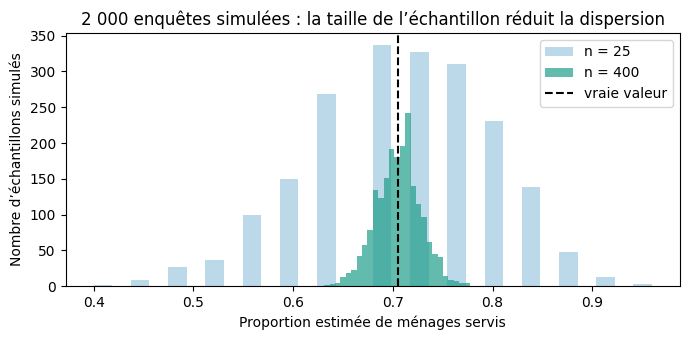

In [ ]:
import numpy as np # pour les operation numeriques
import matplotlib.pyplot as plt  # pour les representations graphiques

# Population synthétique : 5 000 ménages, chacun servi avec une probabilité de 70 % (True = servi)
population = rng.random(5000) < 0.70

# Fonction qui simule une enquête de taille donnée
def estimer(taille_echantillon):
    """Tire un échantillon sans remise et renvoie la proportion de ménages servis."""
    # Tirer des ménages au hasard (sans remise) et calculer la part de True
    return rng.choice(population, size=taille_echantillon, replace=False).mean()

# Dictionnaire vide : il contiendra les estimations pour chaque taille d'échantillon
resultats = {}
# Trois tailles d'enquête à comparer
for n in [25, 100, 400]:
    # Simuler 2 000 enquêtes de taille n
    estimations = np.array([estimer(n) for _ in range(2000)])
    # Ranger ces estimations sous la clé n
    resultats[n] = estimations
    # Intervalle qui contient 95 % des estimations (percentiles 2,5 et 97,5)
    bas, haut = np.percentile(estimations, [2.5, 97.5])
    # Afficher l'intervalle et sa largeur ({n:>3} aligne le nombre à droite sur 3 caractères)
    print(f"n = {n:>3} : 95 % des estimations entre {bas:.1%} et {haut:.1%} (largeur {haut - bas:.1%})")
#----------------------------------------------------------------------------------------------------------
# Créer la figure  # GRAPH
fig, ax = plt.subplots(figsize=(7, 3.5))
# Deux tailles à superposer, chacune avec sa couleur
for n, couleur in zip([25, 400], ["#9ecae1", "#1f9e89"]): # Code de couleur
    # Histogramme des 2 000 estimations pour cette taille
    ax.hist(resultats[n], bins=30, alpha=0.7, color=couleur, label=f"n = {n}")
# Ligne verticale : la vraie proportion dans la population
ax.axvline(population.mean(), color="black", linestyle="--", label="vraie valeur")
# Titre de l'axe horizontal
ax.set_xlabel("Proportion estimée de ménages servis")
# Titre de l'axe vertical
ax.set_ylabel("Nombre d’échantillons simulés")
# Titre du graphique
ax.set_title("2 000 enquêtes simulées : la taille de l’échantillon réduit la dispersion")
# Légende
ax.legend()
# Ajuster les marges
plt.tight_layout()
# Afficher le graphique
plt.show()

**À retenir :** la dispersion diminue comme 1/√n. Multiplier l’échantillon par 4 divise la largeur par 2. C’est l’idée de l’**erreur standard**, que le module 4 transformera en intervalle de confiance.

---
# Scénario 5 — Matrice des précipitations et de l’exposition aux inondations [CAS PRINCIPAL]
*Semaine 4* · Données : `S05_pluie_7jours.csv` (synthétiques)

### Contexte
Une semaine de fortes pluies a touché six communes côtières, de Gonaïves à Jacmel. Des stations météorologiques ont enregistré la pluie tombée chaque jour, et une enquête indique quelle part des ménages vit en zone inondable. L’équipe de réduction des risques ne peut pas envoyer d’inspecteurs partout en même temps : elle doit choisir où vérifier en premier les digues, les ravines et les abris. Vous travaillerez avec NumPy sur un tableau de chiffres, où chaque ligne est une commune et chaque colonne un jour.

## PAUSE — Discutez de la tâche analytique avant de toucher au clavier
Travaillez en binôme ou en petit groupe pendant **10 à 20 minutes**. Consignez les six réponses avant de coder.

**1. Quelle décision pourrait évoluer ?**  
_Votre réponse :_ _______________________________________________

**2. Qui est la partie prenante ?**  
_Votre réponse :_ _______________________________________________

**3. Que représente une ligne ?**  
_Votre réponse :_ _______________________________________________

**4. Quels champs et quelles unités sont nécessaires ?**  
_Votre réponse :_ _______________________________________________

**5. À quoi doit ressembler le résultat ?**  
_Votre réponse :_ _______________________________________________

**6. De quelles façons la réponse pourrait-elle être erronée ?**  
_Votre réponse :_ _______________________________________________

### Avant de coder, mettez-vous d’accord sur
- l’unité d’analyse et le grain d’une ligne ;
- les champs requis et leurs unités ;
- au moins deux contrôles de validation ;
- la forme du résultat final attendu.

> ⚠️ **Ce jeu de données contient au moins un piège propre à ce scénario.** Trouvez-le et expliquez-le avant de conclure.

In [2]:
# 1- Install (PIP) 2- LIBRAIRIES
import io
import pandas as pd
import numpy as np
from google.colab import files
from datetime import datetime, timedelta

In [3]:
# Téléverser le fichier
uploaded = files.upload()

Saving S05_pluie_7jours.csv to S05_pluie_7jours.csv


In [4]:
print(type(uploaded))
print(uploaded.keys())

<class 'dict'>
dict_keys(['S05_pluie_7jours.csv'])


In [5]:
pluie_df = pd.read_csv("S05_pluie_7jours.csv")
display(pluie_df)

,commune,j1,j2,j3,j4,j5,j6,j7,part_menages_zone_inondable
0,Gonaïves,12,18,44,96,72,31,20,0.35
1,Saint-Marc,10,14,38,88,69,27,17,0.22
2,Cabaret,8,16,51,110,83,42,25,0.41
3,Léogâne,6,11,29,75,58,24,15,0.30
4,Petit-Goâve,15,21,63,124,-999,48,32,0.38
5,Jacmel,9,12,35,81,64,30,19,0.18


In [6]:
#Tableau numpy des noms de communes
communes=pluie_df["commune"].to_numpy()

In [7]:
print(communes)
print(communes.shape)

['Gonaïves' 'Saint-Marc' 'Cabaret' 'Léogâne' 'Petit-Goâve' 'Jacmel']
(6,)


In [8]:
# Tableau NumPy 6 × 7 des pluies (colonnes j1 à j7), en nombres décimaux   # pluie = pluie_df[[f"j{i}" for  i  in  range  (1, 8)]].to_numpy().astype=float
pluie = pluie_df[[f"j{i}" for  i  in  range  (1, 8)]].to_numpy(dtype=float)
print(pluie)
print(pluie.shape)


[[  12.   18.   44.   96.   72.   31.   20.]
 [  10.   14.   38.   88.   69.   27.   17.]
 [   8.   16.   51.  110.   83.   42.   25.]
 [   6.   11.   29.   75.   58.   24.   15.]
 [  15.   21.   63.  124. -999.   48.   32.]
 [   9.   12.   35.   81.   64.   30.   19.]]
(6, 7)


In [9]:
# Trois contrôles :  forme, type, min
print("forme:",pluie.shape, "| type :", pluie.dtype, "| min :", pluie.min())


forme: (6, 7) | type : float64 | min : -999.0


In [10]:
# Cumul naïf par commune
print ("Cumul naïf (mm):", dict( zip ( communes, pluie.sum(axis=1))))

Cumul naïf (mm): {'Gonaïves': np.float64(293.0), 'Saint-Marc': np.float64(263.0), 'Cabaret': np.float64(335.0), 'Léogâne': np.float64(218.0), 'Petit-Goâve': np.float64(-696.0), 'Jacmel': np.float64(250.0)}


In [11]:
# Cumul naïf par commune. Enlever le Type. Utiliser ".tolist()"
print ("Cumul naïf (mm):", dict( zip ( communes, pluie.sum(axis=1).tolist())))

Cumul naïf (mm): {'Gonaïves': 293.0, 'Saint-Marc': 263.0, 'Cabaret': 335.0, 'Léogâne': 218.0, 'Petit-Goâve': -696.0, 'Jacmel': 250.0}


In [12]:
#Masque bolean : True  où la station a enregistre le code (-999)
sentinelle = pluie == -999
#Nombre de valeurs sentinelles, dans quelles communes
print("Nombre de valeurs sentinelles par commune :", int(sentinelle.sum()), "->", communes[sentinelle.any(axis=1)])



Nombre de valeurs sentinelles par commune : 1 -> ['Petit-Goâve']


In [13]:
#Remplacer ces valaeurs par NaN (valeur manquante) au lieu de les additioner  # NaN est par defaut a "float".
pluie[sentinelle] = np.nan

# Controle 1: la forme est inchangée, pluviometrie  non negative.
# option advance  : assert pluie.shape == (6,7) and  np.nanmin(pluie) >=0
assert pluie.shape == (6,7)
assert np.nanmin(pluie) >=0

In [14]:
print(pluie)
print(pluie.shape)

[[ 12.  18.  44.  96.  72.  31.  20.]
 [ 10.  14.  38.  88.  69.  27.  17.]
 [  8.  16.  51. 110.  83.  42.  25.]
 [  6.  11.  29.  75.  58.  24.  15.]
 [ 15.  21.  63. 124.  nan  48.  32.]
 [  9.  12.  35.  81.  64.  30.  19.]]
(6, 7)


In [23]:
# Nombre de jours avec une mesure valide, par commune. "~" est le NON logique pour les tableaux booléens, il inverse le masque, donc les cases valides  deviennes "True"
jours_valides = (~np.isnan(pluie)).sum(axis=1)
print("Nombre de jours avec une mesure valide, par commune :", jours_valides)

Nombre de jours avec une mesure valide, par commune : [7 7 7 7 6 7]


In [24]:
#Cumul observe en ignorant les  NaN
cumul_observe= np.nansum(pluie, axis=1)
print("Cumul observé (mm):", dict( zip ( communes, cumul_observe.tolist())))


Cumul observé (mm): {'Gonaïves': 293.0, 'Saint-Marc': 263.0, 'Cabaret': 335.0, 'Léogâne': 218.0, 'Petit-Goâve': 303.0, 'Jacmel': 250.0}


In [25]:
# Cumul sur 7 jours
cumul_observe_7j= cumul_observe/jours_valides * 7
print("Cumul observé sur 7 jours (mm):", dict( zip ( communes, cumul_observe_7j.tolist())))

Cumul observé sur 7 jours (mm): {'Gonaïves': 293.0, 'Saint-Marc': 263.0, 'Cabaret': 335.0, 'Léogâne': 218.0, 'Petit-Goâve': 353.5, 'Jacmel': 250.0}


In [26]:
# Pluie maximale d 'une journée par commune
pluie_max = np.nanmax(pluie, axis=1)
print("Pluie maximale d'une journée (mm):", dict( zip ( communes, pluie_max.tolist())))

Pluie maximale d'une journée (mm): {'Gonaïves': 96.0, 'Saint-Marc': 88.0, 'Cabaret': 110.0, 'Léogâne': 75.0, 'Petit-Goâve': 124.0, 'Jacmel': 81.0}


In [27]:
# Part de menages vivant en zone inondable (0,1)
exposition = pluie_df["part_menages_zone_inondable"].to_numpy()
print("Part de menages vivant en zone inondable :", dict( zip ( communes, exposition.tolist())))

Part de menages vivant en zone inondable : {'Gonaïves': 0.35, 'Saint-Marc': 0.22, 'Cabaret': 0.41, 'Léogâne': 0.3, 'Petit-Goâve': 0.38, 'Jacmel': 0.18}


In [29]:
resultat = pd.DataFrame(columns=["commune", "jours_valides", "cumul_observe_mm", "cumul_estime_7j_mm", "max_journalier_mm", "indice_exposition", "verification_prioritaire"])
resultat["commune"] = communes
resultat["jours_valides"] = jours_valides
resultat["cumul_observe_mm"] = cumul_observe
resultat["cumul_estime_7j_mm"] = cumul_observe_7j
resultat["max_journalier_mm"] = pluie_max
resultat["indice_exposition"] = exposition
resultat["verification_prioritaire"] = (resultat["cumul_observe_mm"] > 300) | (resultat["max_journalier_mm"] > 100)
display(resultat)

,commune,jours_valides,cumul_observe_mm,cumul_estime_7j_mm,max_journalier_mm,indice_exposition,verification_prioritaire
0,Gonaïves,7,293.0,293.0,96.0,0.35,False
1,Saint-Marc,7,263.0,263.0,88.0,0.22,False
2,Cabaret,7,335.0,335.0,110.0,0.41,True
3,Léogâne,7,218.0,218.0,75.0,0.30,False
4,Petit-Goâve,6,303.0,353.5,124.0,0.38,True
5,Jacmel,7,250.0,250.0,81.0,0.18,False


In [30]:
part_jour_4 = pd.DataFrame(columns=["commune", "part_jour_4(%)"])
part_jour_4["commune"] = communes
# part_jour_4["part_jour_4(%)"] = jours_valides.mean(axis=1) * 100
part_jour_4["part_jour_4(%)"] = ((pluie_df['j4'] / cumul_observe) * 100).round(0).astype(int)
display(part_jour_4)

,commune,part_jour_4(%)
0,Gonaïves,33
1,Saint-Marc,33
2,Cabaret,33
3,Léogâne,34
4,Petit-Goâve,41
5,Jacmel,32


In [31]:
# Nombre de jours avec une mesure valide, par commune
nb_jours_valides = (~np.isnan(pluie)).sum(axis=1)

# Cumul observé en ignorant les NaN
cumul_obs = np.nansum(pluie, axis=1)

# Cumul estimé sur 7 jours (hypothèse : jour manquant = moyenne des autres)
cumul_est = (cumul_obs / nb_jours_valides) * 7

# Pluie maximale d'une seule journée, par commune
max_jour = np.nanmax(pluie, axis=1)

# Part des ménages vivant en zone inondable (entre 0 et 1)
part_menages_inondable = pluie_df["part_menages_zone_inondable"].to_numpy()

# Indice d'exposition = pluie estimée (mm) × part des ménages exposés
ind_exposition = cumul_est * part_menages_inondable

# Broadcasting : diviser chaque ligne (6 × 7) par son cumul en colonne (6 × 1)
part_par_jour_relative = pluie / cumul_obs[:, np.newaxis]

# Part du 4e jour (indice 3) dans le cumul de chaque commune, en %
part_jour_4_pct = part_par_jour_relative[:, 3] * 100

# Contrôle 2 : recalcul à la main du cumul de Gonaïves
idx_gonaives = list(communes).index("Gonaïves")
cumul_gonaives_main = np.nansum(pluie[idx_gonaives])
assert np.isclose(cumul_gonaives_main, 293.0), f"Erreur contrôle cumul : {cumul_gonaives_main} au lieu de 293.0"

# Assembler la table finale à partir des tableaux calculés (indice arrondi)
table_finale = pd.DataFrame({
    "commune": communes,
    "jours_valides": nb_jours_valides,
    "cumul_observe_mm": cumul_obs,
    "cumul_estime_7j_mm": cumul_est.round(1),
    "max_journalier_mm": max_jour,
    "indice_exposition": ind_exposition.round(1),
    "part_jour_4_pct": part_jour_4_pct.round(0).astype(int)
})

# Règle : vérification prioritaire si > 300 mm OU > 100 mm/j
table_finale["verification_prioritaire"] = (table_finale["cumul_observe_mm"] > 300) | (table_finale["max_journalier_mm"] > 100)

# Trier de l'indice le plus élevé au plus faible et renuméroter
table_finale = table_finale.sort_values(by="indice_exposition", ascending=False).reset_index(drop=True)

# Afficher la table finale
display(table_finale)

,commune,jours_valides,cumul_observe_mm,cumul_estime_7j_mm,max_journalier_mm,indice_exposition,part_jour_4_pct,verification_prioritaire
0,Cabaret,7,335.0,335.0,110.0,137.4,33,True
1,Petit-Goâve,6,303.0,353.5,124.0,134.3,41,True
2,Gonaïves,7,293.0,293.0,96.0,102.6,33,False
3,Léogâne,7,218.0,218.0,75.0,65.4,34,False
4,Saint-Marc,7,263.0,263.0,88.0,57.9,33,False
5,Jacmel,7,250.0,250.0,81.0,45.0,32,False


### Rapport d'analyse : Matrice des précipitations et de l'exposition aux inondations

**À :** Équipe de réduction des risques et autorités communales  
**De :** Analyste de données d'urgence  
**Objet :** Matrice des précipitations et de l'exposition aux inondations – constats et recommandations  

---

#### Partie 1 – Analyse

À la suite d’une semaine de fortes précipitations ayant durement touché six communes côtières du pays, allant de Gonaïves à Jacmel, il est devenu indispensable d'optimiser l'allocation des ressources de secours sur le terrain. L'objectif principal de ce rapport est d'identifier les zones géographiques prioritaires nécessitant une inspection immédiate des infrastructures de protection, telles que les digues, les ravines et les abris d'urgence. Cette démarche implique directement l'équipe de réduction des risques ainsi que les administrations municipales de chaque commune concernée comme principales parties prenantes de la sécurité civile.

Lors de l'analyse initiale des relevés météorologiques, un piège majeur a été détecté sous la forme d'une valeur aberrante de -999.0 mm au jour 5 pour la station de Petit-Goâve. Cette valeur extrême représentait en réalité un code sentinelle utilisé par la station pour signaler une panne de capteur ou une absence temporaire de transmission. Si cette valeur avait été intégrée naïvement dans nos calculs, Petit-Goâve aurait présenté un cumul de pluie absurde et négatif de -696.0 mm, faussant ainsi totalement l'évaluation des risques. Pour corriger cette anomalie sans introduire de biais, nous avons neutralisé ce code en le déclarant comme une valeur manquante. Afin d'estimer de manière réaliste la pluviométrie totale sur 7 jours pour Petit-Goâve, le jour manquant a été comblé en lui attribuant la moyenne des 6 autres jours valides observés dans cette même commune.

Le tableau A ci-dessous présente la synthèse des observations de pluviométrie collectées ainsi que le calcul de l'indice d'exposition pour chaque commune.

##### Tableau A : Synthèse des précipitations, de l'exposition et niveau de priorité

| Commune | Jours valides | Cumul observé (mm) | Cumul estimé sur 7j (mm) | Maximum journalier (mm) | Part ménages exposés (%) | Indice d'exposition | Vérification prioritaire |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **Cabaret** | 7 | 335.0 | 335.0 | 110.0 | 41.0 % | 137.4 | **Oui (Prioritaire)** |
| **Petit-Goâve** | 6 | 303.0 | 353.5 | 124.0 | 38.0 % | 134.3 | **Oui (Prioritaire)** |
| **Gonaïves** | 7 | 293.0 | 293.0 | 96.0 | 35.0 % | 102.6 | Non |
| **Léogâne** | 7 | 218.0 | 218.0 | 75.0 | 30.0 % | 65.4 | Non |
| **Saint-Marc** | 7 | 263.0 | 263.0 | 88.0 | 22.0 % | 57.9 | Non |
| **Jacmel** | 7 | 250.0 | 250.0 | 81.0 | 18.0 % | 45.0 | Non |

L'indice d'exposition calculé croise la sévérité du climat avec la vulnérabilité sociale locale. Plus précisément, cet indice multiplie le cumul de pluie estimé sur 7 jours par la part des ménages de la commune résidant dans des zones historiquement inondables. Grâce à cette méthodologie, nous pouvons classer objectivement les communes de la plus exposée à la moins exposée : Cabaret arrive en tête (indice de 137.4), suivie de très près par Petit-Goâve (134.3), puis Gonaïves (102.6), Léogâne (65.4), Saint-Marc (57.9) et enfin Jacmel (45.0).

Pour déterminer quelles zones requièrent des inspections physiques immédiates, nous avons établi une règle de vérification prioritaire stricte. Une commune est classée comme hautement prioritaire si son cumul de pluie observé dépasse le seuil critique de 300 mm sur l'ensemble de la période, ou si elle a subi un événement de pluie extrême supérieur à 100 mm en une seule journée. En appliquant ces critères, Cabaret et Petit-Goâve sont les deux seules municipalités qui se qualifient pour une intervention d'urgence. Cabaret dépasse en effet simultanément les deux critères avec un cumul de 335.0 mm et un pic journalier de 110.0 mm. Petit-Goâve déclenche également cette alerte avec 303.0 mm accumulés et surtout le record de précipitation maximale de notre échantillon s'élevant à 124.0 mm en 24 heures.

L'analyse temporelle met par ailleurs en évidence un phénomène météorologique d'une intensité remarquable au cours du quatrième jour de la semaine. Le tableau B met en relief la part représentée par cette seule journée dans le bilan hydrologique global des différentes localités.

##### Tableau B : Poids relatif des précipitations du Jour 4 par commune

| Commune | Pluie cumulée Jour 4 (mm) | Part du Jour 4 dans le cumul (%) |
| :--- | :---: | :---: |
| **Petit-Goâve** | 124.0 | 41 % |
| **Léogâne** | 75.0 | 34 % |
| **Saint-Marc** | 88.0 | 33 % |
| **Cabaret** | 110.0 | 33 % |
| **Gonaïves** | 96.0 | 33 % |
| **Jacmel** | 81.0 | 32 % |

Ce quatrième jour a concentré à lui seul plus d'un tiers des précipitations totales de toute la semaine pour l'ensemble des communes de la région. À Petit-Goâve, cette concentration atteint un niveau extrême où une seule journée de tempête a représenté 41 % de l'eau reçue en sept jours. Ce pic d'intensité brutal explique la forte probabilité de crues soudaines et de saturation immédiate des sols observée dans ces localités.

Malgré la solidité globale de notre modèle, certaines limites techniques doivent être gardées à l'esprit lors de la prise de décision. En particulier, l'estimation linéaire du jour manquant à Petit-Goâve suppose que la pluie y a été modérée ce jour-là, alors que la réalité terrain aurait pu présenter une sécheresse ou au contraire une autre tempête locale. De plus, il convient de souligner que toutes les données analysées ici sont synthétiques et ont été générées à des fins de planification stratégique et d'apprentissage opérationnel.

---

#### Partie 2 – Recommandations

1. **Déploiement immédiat des inspecteurs de digues à Cabaret et Petit-Goâve :** En raison d'un cumul observé dépassant les seuils d'alerte (335.0 mm à Cabaret et 303.0 mm à Petit-Goâve), les équipes techniques de génie civil doivent être dépêchées en priorité dans ces deux communes sous 24 heures pour évaluer la résistance structurelle des digues fluviales.
2. **Sécurisation des zones à fort taux d'exposition résidentielle :** À Cabaret, où 41.0 % des ménages habitent en zone inondable, et à Petit-Goâve (38.0 % d'exposition), il est crucial de valider la viabilité des abris temporaires d'urgence et de préparer des plans d'évacuation préventifs ciblés sur ces quartiers hautement vulnérables.
3. **Modernisation et redondance du réseau de stations de mesure :** Suite à la perte de données enregistrée au jour 5 à Petit-Goâve (mesure absente compensée mathématiquement à 50.5 mm), il est recommandé d'équiper la station locale de capteurs redondants et d'une batterie de secours afin de garantir des séries de données d'urgence complètes sans devoir recourir à des estimations statistiques.

### Étapes
1. Construire un tableau NumPy (6 communes × 7 jours) ; afficher forme, type, minimum.
2. Prédire puis calculer le cumul naïf par commune. Quelle valeur est absurde ?
3. Remplacer la valeur sentinelle par NaN grâce à un masque booléen.
4. Calculer cumul observé, cumul estimé sur 7 jours, maximum journalier et indice d’exposition.
5. Signaler une vérification prioritaire si cumul > 300 mm ou maximum journalier > 100 mm.

*Indice : Fonctions utiles : `.to_numpy(dtype=float)`, `tableau == -999`, `np.nan`, `np.nansum`, `np.nanmax`, `axis=1`.*

In [ ]:
# À FAIRE — scénario 5 : écrivez votre code ci-dessous, en suivant les étapes.
# Gardez chaque transformation visible et ajoutez vos deux contrôles avec assert.


# AFFICHAGE OBLIGATOIRE DE LA TABLE FINALE
# display(resultat)

### Après le code — réflexion obligatoire
**Conclusion :**
**Preuves (avec unités) :**
**Limite :**
**Étape suivante :**

**Contrôle de validation 1 :**
**Contrôle de validation 2 :**
**Piège trouvé dans les données :**

### Note à la partie prenante — à rédiger après avoir inspecté votre table finale
Rédigez une **note de 120 à 180 mots**. Ne décrivez pas Python : expliquez ce que le résultat signifie pour la décision. Elle doit contenir une recommandation, **au moins deux résultats chiffrés avec leurs unités**, leur interprétation, une limite et une étape suivante.

_À : Équipe de réduction des risques et autorités communales_
_Objet : Matrice des précipitations et de l’exposition aux inondations — point analytique_

__________________________________________________________________

---
## Semaine 4 — Récapitulatif : qu’avons-nous appris aujourd’hui ?
- Construire, indexer et filtrer un tableau NumPy.
- Remplacer des calculs manuels par une opération vectorisée.
- Simuler des échantillons pour observer la variabilité d’une estimation.

### Rappel actif — sans exécuter de code
1. **Un concept que je peux expliquer :** __________________________________________
2. **Un contrôle que j’utiliserais :** _____________________________________________
3. **Une erreur que je sais maintenant éviter :** _______________________________

---
# Vérification de fin de module
Avant la remise :
- [ ] J’ai répondu aux questions analytiques avant de coder.
- [ ] Je peux expliquer l’unité d’analyse et les unités de mesure essentielles.
- [ ] J’ai trouvé et expliqué le piège de chaque scénario.
- [ ] J’ai utilisé au moins deux contrôles de validation pertinents.
- [ ] J’ai indiqué que les données pédagogiques sont synthétiques.
- [ ] J’ai redémarré le noyau et exécuté toutes les cellules dans l’ordre.
- [ ] Mon résultat final présente une conclusion, des preuves, une limite et une étape suivante.
- [ ] J’ai rempli la déclaration d’usage de l’IA.

## Déclaration d’usage de l’IA (obligatoire)
| Question | Votre réponse |
|---|---|
| Avez-vous utilisé un assistant d’IA ? Lequel ? | |
| Pour quelle(s) tâche(s) précise(s) ? | |
| Qu’avez-vous gardé, modifié ou rejeté ? | |
| Comment avez-vous vérifié ? | |
| Avez-vous transmis des données ? Lesquelles ? | |

## Ticket de sortie du module
Répondez en quelques phrases, sans code :
1. **Quel concept pouvez-vous désormais expliquer sans code ?**
   *Ce que la question signifie :* montrez que vous comprenez l’idée, pas seulement la syntaxe.
2. **Quel contrôle permettrait de détecter une erreur grave dans le scénario d’aujourd’hui ?**
   *Ce que la question signifie :* proposez une vérification concrète capable d’empêcher une conclusion erronée.
3. **Quelle incertitude ou limite subsiste ?**
   *Ce que la question signifie :* précisez ce que les données ou la méthode ne permettent pas d’affirmer.